# **RNN과 자연어처리**


---



**(코랩에서)한글 폰트 지정하는 방법**

In [ ]:
# 코랩에서 실행
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import shutil
import warnings
import logging

# ── 1. 나눔 폰트 설치 ──────────────────────────────────────────
!apt-get install -y fonts-nanum > /dev/null 2>&1

# ── 2. matplotlib 캐시 디렉터리 삭제 ──────────────────────────
shutil.rmtree(mpl.get_cachedir(), ignore_errors=True)

# ── 3. 폰트 등록 및 유니코드 마이너스 경고 방지 ──────────────────
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (6, 4)

# 수학 기호(마이너스 등)를 일반 텍스트로 처리하도록 설정하여 폰트 에러 차단
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.default'] = 'regular'

# mathtext 및 font_manager 관련 폰트 결함 경고 완전히 무시 설정
logging.getLogger('matplotlib.mathtext').setLevel(logging.ERROR)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib.font_manager')



---



# **4. 생성하는 RNN → Seq2Seq → Attention**, 그리고 RNN의 귀환

| Lab | 주제 | 발전사 위치 |
|---|---|---|
| 4-1 | 온도(temperature)가 생성 결과를 바꾸는 원리 | 샘플링 |
| 4-2 | 문자 단위 LSTM으로 "가짜 영화평" 생성기 | 2013 Graves · 2015 char-RNN |
| 4-3 |  날짜 번역기: Seq2Seq vs Seq2Seq + Attention, 어텐션 지도 보기 | 2014 Sutskever · 2015 Bahdanau |
| 4-4 |  minGRU: 병렬로 학습되는 RNN 20줄 구현 | 2024 Feng et al. "Were RNNs All We Needed?" |

In [ ]:
%pip install -q koreanize-matplotlib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, urllib.request, time, random, json, datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False   # 음수 기호 깨짐 방지
import torch, torch.nn as nn, torch.nn.functional as F

def seed_all(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all()
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("figs", exist_ok=True)

---
## **4-1. 온도(temperature)**
— $p_i = \dfrac{\exp(z_i/T)}{\sum_j \exp(z_j/T)}$

In [ ]:
words = ["재밌", "최고", "지루", "노잼"]
logits = torch.tensor([2.0, 1.0, 0.5, 0.1])
for T in [0.5, 1.0, 2.0]:
    p = torch.softmax(logits / T, 0)
    print(f"T={T}: " + "  ".join(f"{w} {v:.2f}" for w, v in zip(words, p)))
# T↓ → 가장 그럴듯한 단어만 (보수적·반복)   T↑ → 고르게 (창의적·엉뚱)

T=0.5: 재밌 0.83  최고 0.11  지루 0.04  노잼 0.02
T=1.0: 재밌 0.57  최고 0.21  지루 0.13  노잼 0.09
T=2.0: 재밌 0.41  최고 0.25  지루 0.19  노잼 0.16


---
## **4-2. 문자 단위 LSTM 언어 모델** — 긍정 영화평을 학습해 새 리뷰 만들기
목표: 앞 문자들 $c_1..c_{t-1}$로 다음 문자 $c_t$ 맞히기, 손실 = 교차 엔트로피 (= 1교시 n-gram과 같은 목표, 문맥 길이만 무한대)

In [ ]:
if not os.path.exists("ratings_train.txt"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt", "ratings_train.txt")
nsmc = pd.read_csv("ratings_train.txt", sep="\t").dropna()
pos = [d.strip() for d in nsmc[nsmc.label == 1].document if 10 <= len(d.strip()) <= 80]
text = "\n".join(pos)
cnt = pd.Series(list(text)).value_counts()
chars = ["?"] + sorted(cnt[cnt >= 20].index)          # 드문 문자는 '?'로
c2i = {c: i for i, c in enumerate(chars)}
data = torch.tensor([c2i.get(c, 0) for c in text])
print(f"긍정 리뷰 {len(pos):,}개 | 문자 {len(data):,}개 | 문자 어휘 {len(chars):,}개")

긍정 리뷰 61,942개 | 문자 1,920,974개 | 문자 어휘 1,145개


In [ ]:
class CharLSTM(nn.Module):
    def __init__(self, V, emb=64, hidden=256):
        super().__init__()
        self.emb, self.lstm, self.fc = nn.Embedding(V, emb), nn.LSTM(emb, hidden, batch_first=True), nn.Linear(hidden, V)
    def forward(self, x, state=None):
        out, state = self.lstm(self.emb(x), state)
        return self.fc(out), state

@torch.no_grad()
def sample(model, prompt="이 영화", n=60, T=0.8):
    model.eval()
    x = torch.tensor([[c2i.get(c, 0) for c in prompt]], device=device)
    out, state = model(x)
    s = prompt
    for _ in range(n):
        p = torch.softmax(out[0, -1] / T, 0)
        nxt = torch.multinomial(p, 1).item()
        if chars[nxt] == "\n":
            break
        s += chars[nxt]
        out, state = model(torch.tensor([[nxt]], device=device), state)
    return s

seed_all(0)
lm = CharLSTM(len(chars)).to(device)
opt = torch.optim.Adam(lm.parameters(), lr=3e-3)
SEQ, BS, STEPS = 64, 64, 1000                       # ⏱ CPU 약 3분 (GPU라면 STEPS를 3000으로 늘려 보자)
losses, snapshots = [], {}
t0 = time.time()
for step in range(1, STEPS + 1):
    lm.train()
    starts = torch.randint(0, len(data) - SEQ - 1, (BS,))
    x = torch.stack([data[s:s+SEQ] for s in starts]).to(device)
    y = torch.stack([data[s+1:s+SEQ+1] for s in starts]).to(device)   # 한 칸 밀린 정답
    logits, _ = lm(x)
    loss = F.cross_entropy(logits.reshape(-1, len(chars)), y.reshape(-1))
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(lm.parameters(), 1.0); opt.step()
    losses.append(loss.item())
    if step in (1, 100, 300, STEPS):
        seed_all(step); snapshots[step] = sample(lm, "이 영화", T=0.8)
        print(f"step {step:>4} loss {loss.item():.2f} ({time.time()-t0:.0f}s) | {snapshots[step]}")

step    1 loss 7.04 (0s) | 이 영화무3할쨌렌봐길엠~셈티켜질춰퇴C국헌승쌍기꾸혜엮r낭뎅카쩔묘밴혈oE셈낮더졌양탱간른♥짐깁빨월삶태앙화쏘ㅁ황투웃퀴렀죽래


step  100 loss 3.73 (10s) | 이 영화


step  300 loss 3.23 (30s) | 이 영화..남이 윌으로 드라마 스토리의 인간 자연이 예단하는 흥미있는데.. 중의 최고의 영화


step 1000 loss 2.87 (98s) | 이 영화인데, 김민혜의 일로 표현해서 볼수 있다.


In [ ]:
for T in [0.3, 0.8, 1.3]:
    seed_all(7)
    print(f"[T={T}]")
    for p in ["이 영화", "배우들", "마지막 장면"]:
        print("   ", sample(lm, p, T=T))

[T=0.3]
    이 영화를 보고 싶다.
    배우들의 연기가 너무 아름다운 영화.
    마지막 장면은 아직도 생생 최고의 영화. 그래도 재밌게 봤습니다.
[T=0.8]
    이 영화라서 재밌게 봤다는
    배우들의 연기력도 아니유
    마지막 장면이 고대됨
[T=1.3]
    이 영화라서 재밌게 잘감후
    배우들은 원작응도란닌한유루가없고빵엇네대하긋나6점!
    마지막 장면뭐키면(6점위납고불해놓게냄영화인데우양한ㅋㅋ정전노가


**🎯 미션**: 부정 리뷰(`label == 0`)로 학습한 모델과 비교해 보자. 같은 "이 영화"로 시작해도 이어지는 말이 어떻게 달라질까?

---
## **4-3. 날짜 번역기** — 고정 길이 벡터의 병목과 어텐션
입력: `2026년 10월 30일 금요일`, `Oct 30, 2026`, `30/10/26` … → 출력: `2026-10-30`

In [ ]:
MON = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MONTH = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
WD = "월화수목금토일"
def random_date():
    d = datetime.date(1950, 1, 1) + datetime.timedelta(days=random.randint(0, 36500))
    fmts = [f"{d.year}년 {d.month}월 {d.day}일",
            f"{d.year}년 {d.month}월 {d.day}일 {WD[d.weekday()]}요일",
            f"{d.year%100:02d}.{d.month:02d}.{d.day:02d}",
            f"{d.year}. {d.month}. {d.day}.",
            f"{d.day:02d}/{d.month:02d}/{d.year%100:02d}",
            f"{MON[d.month-1]} {d.day}, {d.year}",
            f"{d.day} {MONTH[d.month-1]} {d.year}",
            f"{MONTH[d.month-1].upper()} {d.day}, {d.year}",
            f"{d.year}/{d.month}/{d.day}"]
    return random.choice(fmts), d.isoformat()

seed_all(1)
pairs = [random_date() for _ in range(30000)]
for p in pairs[:6]:
    print(f"{p[0]:<26} → {p[1]}")

src_chars = sorted({c for s, _ in pairs for c in s})
tgt_chars = sorted({c for _, t in pairs for c in t})
SRC = ["<pad>"] + src_chars
TGT = ["<pad>", "<s>", "</s>"] + tgt_chars
s2i, t2i = {c: i for i, c in enumerate(SRC)}, {c: i for i, c in enumerate(TGT)}
SL = max(len(s) for s, _ in pairs)
def enc_pairs(ps):
    X = torch.zeros(len(ps), SL, dtype=torch.long); Y = torch.zeros(len(ps), 12, dtype=torch.long)
    for i, (s, t) in enumerate(ps):
        X[i, :len(s)] = torch.tensor([s2i[c] for c in s])
        Y[i] = torch.tensor([1] + [t2i[c] for c in t] + [2])       # <s> 2026-10-30 </s>
    return X, Y
Xd, Yd = enc_pairs(pairs[:27000]); Xv, Yv = enc_pairs(pairs[27000:])
print("입력 최대 길이", SL, "| 입력 문자", len(SRC), "| 출력 문자", len(TGT))

1974년 2월 9일 토요일            → 1974-02-09
1995년 10월 8일 일요일           → 1995-10-08
NOVEMBER 23, 2038          → 2038-11-23
26 September 2034          → 2034-09-26
1987년 9월 3일 목요일            → 1987-09-03
2037년 7월 15일               → 2037-07-15


입력 최대 길이 18 | 입력 문자 63 | 출력 문자 14


In [ ]:
class Encoder(nn.Module):
    def __init__(self, V, emb=32, hidden=64):
        super().__init__()
        self.emb, self.gru = nn.Embedding(V, emb, padding_idx=0), nn.GRU(emb, hidden, batch_first=True)
    def forward(self, x):
        out, h = self.gru(self.emb(x))           # out: 모든 시점의 은닉 상태, h: 마지막 은닉 상태(=문맥 벡터)
        return out, h

class Decoder(nn.Module):
    """attention=False: 마지막 은닉 상태 하나만 보고 생성 (Sutskever 2014)
       attention=True : 매 시점 인코더 전체를 다시 훑어봄 (Bahdanau 2015, 가산 어텐션)"""
    def __init__(self, V, emb=32, hidden=64, attention=False):
        super().__init__()
        self.attention = attention
        self.emb = nn.Embedding(V, emb)
        self.gru = nn.GRU(emb + (hidden if attention else 0), hidden, batch_first=True)
        self.fc = nn.Linear(hidden * (2 if attention else 1), V)
        if attention:
            self.W_s, self.W_h, self.v = nn.Linear(hidden, hidden), nn.Linear(hidden, hidden), nn.Linear(hidden, 1)
    def step(self, y_prev, h, enc_out, mask):
        e = self.emb(y_prev)                                             # (B,1,E)
        attn = None
        if self.attention:
            # ① 점수 e_tj = vᵀ tanh(W_s s_{t-1} + W_h h_j)  ② softmax → α  ③ 문맥 c_t = Σ α_tj h_j
            score = self.v(torch.tanh(self.W_s(h[-1]).unsqueeze(1) + self.W_h(enc_out))).squeeze(-1)
            score = score.masked_fill(~mask, -1e9)
            attn = torch.softmax(score, dim=1)
            ctx = (attn.unsqueeze(-1) * enc_out).sum(1, keepdim=True)
            out, h = self.gru(torch.cat([e, ctx], -1), h)
            logit = self.fc(torch.cat([out, ctx], -1))
        else:
            out, h = self.gru(e, h)
            logit = self.fc(out)
        return logit.squeeze(1), h, attn

class Seq2Seq(nn.Module):
    def __init__(self, attention):
        super().__init__()
        self.enc, self.dec = Encoder(len(SRC)), Decoder(len(TGT), attention=attention)
    def forward(self, x, y):                                             # 학습: 교사 강요(teacher forcing)
        enc_out, h = self.enc(x); mask = x != 0; logits = []
        for t in range(y.size(1) - 1):
            lg, h, _ = self.dec.step(y[:, t:t+1], h, enc_out, mask); logits.append(lg)
        return torch.stack(logits, 1)
    @torch.no_grad()
    def translate(self, x, max_len=11):                                  # 추론: 자기 출력을 다음 입력으로
        enc_out, h = self.enc(x); mask = x != 0
        y = torch.full((x.size(0), 1), 1, device=x.device); outs, attns = [], []
        for _ in range(max_len):
            lg, h, a = self.dec.step(y, h, enc_out, mask)
            y = lg.argmax(-1, keepdim=True); outs.append(y); attns.append(a)
        return torch.cat(outs, 1), attns

def exact_match(model, X, Y):
    model.eval(); pred, _ = model.translate(X.to(device))
    return (pred[:, :10].cpu() == Y[:, 1:11]).all(1).float().mean().item()

def train_s2s(attention, epochs=6, bs=128):
    seed_all(0); m = Seq2Seq(attention).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=3e-3); hist = []
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xd)); t0 = time.time()
        for i in range(0, len(Xd), bs):
            idx = perm[i:i+bs]; x, y = Xd[idx].to(device), Yd[idx].to(device)
            loss = F.cross_entropy(m(x, y).reshape(-1, len(TGT)), y[:, 1:].reshape(-1))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        hist.append(exact_match(m, Xv, Yv))
        print(f"  {'Attention' if attention else '기본 Seq2Seq'} epoch {ep+1}: 완전 일치 정확도 {hist[-1]:.3f} ({time.time()-t0:.0f}s)")
    return m, hist

s2s_plain, h_plain = train_s2s(attention=False)
s2s_attn,  h_attn  = train_s2s(attention=True)

  기본 Seq2Seq epoch 1: 완전 일치 정확도 0.001 (4s)


  기본 Seq2Seq epoch 2: 완전 일치 정확도 0.034 (4s)


  기본 Seq2Seq epoch 3: 완전 일치 정확도 0.090 (4s)


  기본 Seq2Seq epoch 4: 완전 일치 정확도 0.237 (4s)


  기본 Seq2Seq epoch 5: 완전 일치 정확도 0.421 (4s)


  기본 Seq2Seq epoch 6: 완전 일치 정확도 0.600 (4s)


... (2 outputs left out)

  Attention epoch 3: 완전 일치 정확도 0.999 (9s)


  Attention epoch 4: 완전 일치 정확도 1.000 (10s)


  Attention epoch 5: 완전 일치 정확도 1.000 (9s)


  Attention epoch 6: 완전 일치 정확도 1.000 (8s)


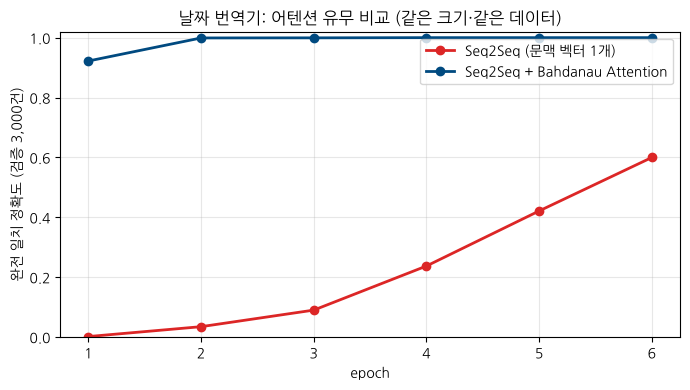

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 7), h_plain, "o-", c="#DC2626", lw=2, label="Seq2Seq (문맥 벡터 1개)")
plt.plot(range(1, 7), h_attn, "o-", c="#004A80", lw=2, label="Seq2Seq + Bahdanau Attention")
plt.ylim(0, 1.02); plt.xlabel("epoch"); plt.ylabel("완전 일치 정확도 (검증 3,000건)")
plt.title("날짜 번역기: 어텐션 유무 비교 (같은 크기·같은 데이터)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figs/s2s_curve.png", dpi=160); plt.show()

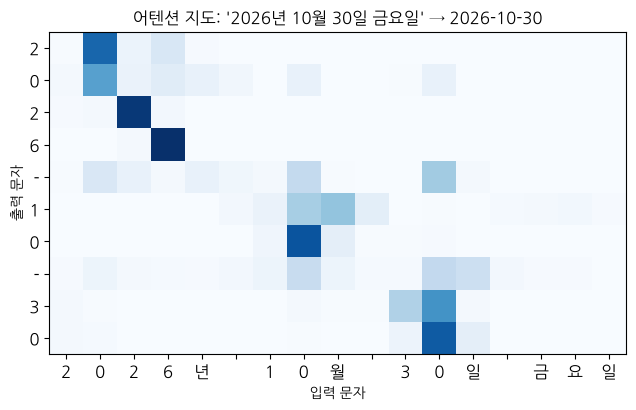

2026-10-30


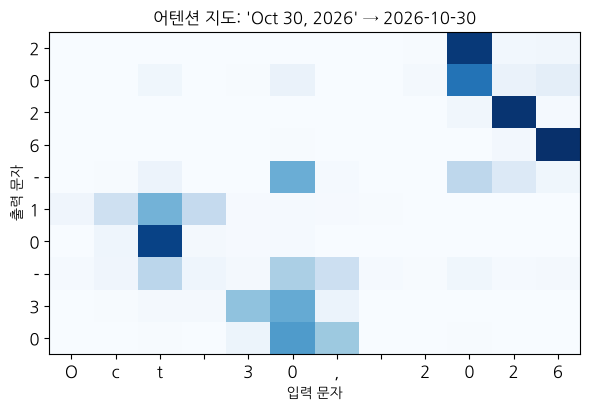

2026-10-30


In [ ]:
def show_attention(s, fn=None):
    x = torch.tensor([[s2i[c] for c in s] + [0] * (SL - len(s))], device=device)
    pred, attns = s2s_attn.translate(x)
    toks = [TGT[i] for i in pred[0, :10].tolist()]               # 출력 문자 10개 (YYYY-MM-DD)
    out = "".join(toks)
    A = torch.stack([a[0, :len(s)] for a in attns[:10]]).cpu().numpy()
    fig, ax = plt.subplots(figsize=(max(6, len(s) * 0.38), 4.2))
    ax.imshow(A, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(s)), list(s), fontsize=12); ax.set_yticks(range(10), toks, fontsize=12)
    ax.set_xlabel("입력 문자"); ax.set_ylabel("출력 문자"); ax.set_title(f"어텐션 지도: '{s}' → {out}")
    plt.tight_layout()
    if fn: plt.savefig(fn, dpi=160)
    plt.show(); return out
print(show_attention("2026년 10월 30일 금요일", "figs/attn_ko.png"))
print(show_attention("Oct 30, 2026", "figs/attn_en.png"))

**관찰**: 연도 `2026`을 쓸 때는 입력의 `2026` 위치를, 월 `10`을 쓸 때는 `10월`/`Oct` 위치를 본다. 요일(`금요일`)은 거의 보지 않는다 — 아무도 가르쳐 주지 않았다!

---
## **4-4. minGRU** — "RNN도 병렬로 학습할 수 있다면?" (Feng et al., 2024)
GRU에서 게이트가 $h_{t-1}$에 의존하지 않도록 단순화하면 $h_t = (1-z_t)\odot h_{t-1} + z_t \odot \tilde h_t$ 는
**선형 점화식** $h_t = a_t h_{t-1} + b_t$ 이 되어, 누적합(scan)으로 모든 시점을 한 번에 계산할 수 있다.

In [ ]:
def g(x):   # 양수 보장 활성화 (논문 식)
    return torch.where(x >= 0, x + 0.5, torch.sigmoid(x))
def log_g(x):
    return torch.where(x >= 0, (F.relu(x) + 0.5).log(), -F.softplus(-x))

class MinGRU(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.lin_z, self.lin_h = nn.Linear(d, h), nn.Linear(d, h)
    def sequential(self, x):                       # RNN처럼 한 칸씩 (추론용)
        z, ht = torch.sigmoid(self.lin_z(x)), g(self.lin_h(x))
        h = torch.zeros(x.size(0), z.size(-1)); outs = []
        for t in range(x.size(1)):
            h = (1 - z[:, t]) * h + z[:, t] * ht[:, t]; outs.append(h)
        return torch.stack(outs, 1)
    def parallel(self, x):                         # 로그 공간 병렬 스캔 (학습용)
        k = self.lin_z(x)
        log_a = -F.softplus(k)                     # log(1 - z)
        log_b = -F.softplus(-k) + log_g(self.lin_h(x))   # log(z · h̃)
        a_star = torch.cumsum(log_a, dim=1)
        return torch.exp(a_star + torch.logcumsumexp(log_b - a_star, dim=1))

torch.manual_seed(0)
mg = MinGRU(16, 32); x = torch.randn(4, 256, 16)
with torch.no_grad():
    print("순차 = 병렬?", torch.allclose(mg.sequential(x), mg.parallel(x), atol=1e-4))
rows = []
for T in [256, 1024, 4096]:
    x = torch.randn(8, T, 16)
    with torch.no_grad():
        t0 = time.time(); mg.sequential(x); ts = time.time() - t0
        t0 = time.time(); mg.parallel(x); tp = time.time() - t0
    rows.append([T, round(ts * 1000, 1), round(tp * 1000, 1), round(ts / tp, 1)])
mingru_df = pd.DataFrame(rows, columns=["시퀀스 길이", "순차(ms)", "병렬 스캔(ms)", "속도 배수"])
mingru_df.to_csv("mingru_speed.csv", index=False)
mingru_df

순차 = 병렬? True


,시퀀스 길이,순차(ms),병렬 스캔(ms),속도 배수
0,256,3.7,2.5,1.5
1,1024,24.2,10.6,2.3
2,4096,82.7,37.6,2.2


In [ ]:
json.dump(dict(snapshots=snapshots, plain=h_plain, attn=h_attn), open("s2s_results.json", "w"), ensure_ascii=False, indent=1)

### 정리
| 시기 | 모델 | 해결한 문제 | 남은 문제 |
|---|---|---|---|
| 2014 | Seq2Seq | 가변 길이 → 가변 길이 | 문맥 벡터 1개 병목 |
| 2015 | + Attention | 필요한 입력을 직접 참조 | 여전히 순차 계산 |
| 2017 | Transformer | RNN 제거, 완전 병렬 | 길이 제곱 비용 → **10차시** |
| 2023~ | Mamba · xLSTM · minGRU · Gated DeltaNet | 선형 비용 + 병렬 학습 | 하이브리드 LLM에서 경쟁 중 |